# 03 · Multirate — โซ่ anti-alias + decimation ที่ออกแบบเอง (Q7)

**โครงงาน Sea Level × Wavelet Coherence · วิชา 01204496 · สัปดาห์ที่ 2 (W2) · บทที่ 3–4**

โน้ตบุ๊กนี้ตอบ **Q7**: *โซ่ anti-alias + decimation ที่ออกแบบเองให้ค่าตรงกับค่าทางการของ PSMSL ไหม*
ซึ่งเป็นวัตถุประสงค์ข้อ 2 ของ proposal และมีเฉลยให้ตรวจจริง

```
UHSLC รายชั่วโมง ──[ FIR Kaiser 70 dB ]──> รายวัน   ⇄ UHSLC daily   (ตัวกรองทางการของ UHSLC)
                 ──[ เฉลี่ยเดือนปฏิทิน ]──> รายเดือน ⇄ PSMSL รายเดือน
                 ──[ เฉลี่ย 12 เดือน ]───> รายปี    ⇄ PSMSL รายปี
```

## เกณฑ์ที่ประกาศไว้ใน proposal §4

| ด้าน | เกณฑ์ |
| --- | --- |
| Filter chain + decimation | เทียบกับค่าเฉลี่ยรายเดือนทางการของ PSMSL — **รายงาน RMSE พร้อมอธิบายที่มาของผลต่างที่เหลือ** |
| Stopband attenuation | ป้อนสัญญาณทดสอบที่ความถี่สูงกว่า Nyquist ใหม่ แล้ววัด attenuation — ต้องไม่ปรากฏในผลที่ decimate แล้ว |
| ผลที่คาดหวังข้อ 2 | กราฟก่อน–หลัง anti-alias filter แสดงว่าถ้า decimate โดยไม่กรองก่อน tide จะพับกลับมาปนอย่างไร |

> ตัวงานอยู่ใน `wtc/multirate.py` (ไม่เรียก `scipy.signal.decimate` / `firwin` / `kaiserord` เลย)
> โน้ตบุ๊กเรียกใช้และตรวจ แล้วเทียบกับ scipy เพื่อยืนยันว่าสูตรที่เขียนเองถูก


In [1]:
import json, sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from wtc.loaders import read_uhslc_grid, read_uhslc_daily, read_psmsl
from wtc.multirate import (TIDES_CPD, compare, daily_to_monthly, decimal_year_to_month,
                           design_lowpass, fir_at, hourly_to_daily, kaiser_beta,
                           kaiser_numtaps, kaiser_window, monthly_mean_direct,
                           monthly_to_annual, naive_daily)
from wtc.plotting import use_thai_font, plot_filter_response, plain_log_ticks

RAW, FIGURES = ROOT / "data" / "raw", ROOT / "figures"
FIGURES.mkdir(exist_ok=True)
use_thai_font()

t, v = read_uhslc_grid(RAW / "uhslc" / "ko_taphao_noi_hourly.csv")
print(f"UHSLC รายชั่วโมง KO TAPHAO NOI: {t[0]} → {t[-1]} · {len(t):,} ชั่วโมง · หาย {np.isnan(v).mean():.2%}")
print("กริดต่อเนื่องทุกชั่วโมง (read_uhslc_grid ตรวจให้แล้ว ถ้าไม่ต่อเนื่องจะล้มทันที)")

UHSLC รายชั่วโมง KO TAPHAO NOI: 1985-01-01T00 → 2019-12-31T16 · 306,785 ชั่วโมง · หาย 3.10%
กริดต่อเนื่องทุกชั่วโมง (read_uhslc_grid ตรวจให้แล้ว ถ้าไม่ต่อเนื่องจะล้มทันที)


## 1. สัญญาณรายชั่วโมงหน้าตาเป็นอย่างไร

สองสัปดาห์แรกของข้อมูลพอให้เห็นว่า **สิ่งที่ครอบงำสัญญาณคือน้ำขึ้นน้ำลง** ไม่ใช่ระดับน้ำทะเลเฉลี่ย
ที่เราสนใจ — แกว่งวันละสองรอบ แอมพลิจูดเป็นเมตร และขนาดเปลี่ยนตามรอบ spring–neap (~14.8 วัน)

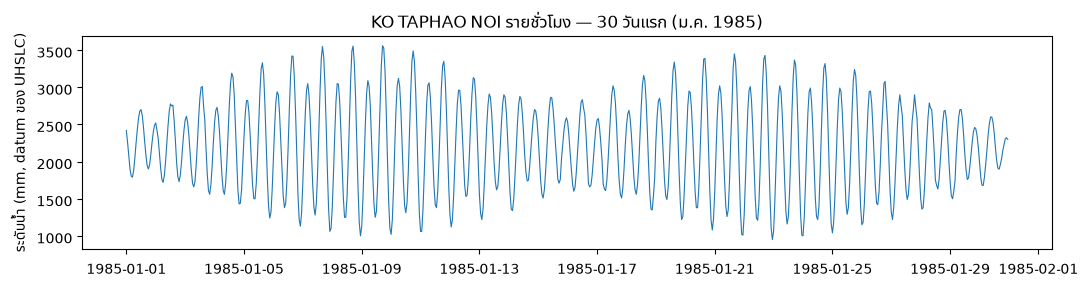

ช่องว่าง 17 ช่วง · สั้นสุด 26 ชม. · ยาวสุด 159 วัน · ชั่วโมงที่หายอยู่ในช่วงยาวเกิน 2 วัน 97.5%


In [2]:
sl = slice(0, 24 * 30)
fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(t[sl], v[sl], lw=0.8)
ax.set_ylabel("ระดับน้ำ (mm, datum ของ UHSLC)")
ax.set_title("KO TAPHAO NOI รายชั่วโมง — 30 วันแรก (ม.ค. 1985)")
fig.tight_layout(); fig.savefig(FIGURES / "w2-hourly-sample.png", dpi=130); plt.show()

miss = np.isnan(v)
e = np.flatnonzero(np.diff(np.r_[0, miss.astype(np.int8), 0]))
runs = e[1::2] - e[::2]
print(f"ช่องว่าง {len(runs)} ช่วง · สั้นสุด {runs.min()} ชม. · ยาวสุด {runs.max()/24:.0f} วัน · "
      f"ชั่วโมงที่หายอยู่ในช่วงยาวเกิน 2 วัน {runs[runs > 48].sum() / miss.sum():.1%}")

## 2. วัดน้ำขึ้นน้ำลงด้วย harmonic analysis — ตัวเลขนี้คือที่มาของสเปกตัวกรอง

ฟิต $v(t) = c_0 + \sum_k \left[a_k\cos(2\pi f_k t) + b_k\sin(2\pi f_k t)\right]$ ด้วย least squares
ที่ความถี่ขององค์ประกอบหลัก 8 ตัว แอมพลิจูด $= \sqrt{a_k^2+b_k^2}$

ถ้า**สุ่มวันละครั้งโดยไม่กรอง** (อัตราใหม่ 1 รอบ/วัน) องค์ประกอบที่ $f_k$ จะพับลงมาที่
$$f_{\text{alias}} = |f_k - \operatorname{round}(f_k)|\ \text{รอบ/วัน}$$

In [3]:
g = np.isfinite(v)
hrs = np.arange(len(v), dtype=float)[g]
cols = [np.ones(g.sum())]
for f in TIDES_CPD.values():
    w = 2 * np.pi * f * hrs / 24
    cols += [np.cos(w), np.sin(w)]
A = np.column_stack(cols)
coef = np.linalg.lstsq(A, v[g], rcond=None)[0]
amp = {k: float(np.hypot(coef[1 + 2*i], coef[2 + 2*i])) for i, k in enumerate(TIDES_CPD)}
explained = 1 - np.var(v[g] - A @ coef) / np.var(v[g])

print(f"น้ำขึ้นน้ำลง 8 องค์ประกอบอธิบายความแปรปรวนรายชั่วโมง {explained:.1%}\n")
print(f"  {'':3s} {'แอมพลิจูด':>10s} {'ความถี่':>11s} {'ถ้าไม่กรอง พับไปที่คาบ':>24s}")
for k, a in sorted(amp.items(), key=lambda x: -x[1]):
    fa = abs(TIDES_CPD[k] - round(TIDES_CPD[k]))
    per = "DC (ค่าคงที่)" if fa < 1e-9 else f"{1/fa:8.1f} วัน"
    print(f"  {k:3s} {a:8.1f} mm {TIDES_CPD[k]:9.4f} cpd {per:>22s}")
alias_K1 = 1 / abs(TIDES_CPD["K1"] - 1)
assert explained > 0.9 and abs(alias_K1 - 365.2) < 0.5

น้ำขึ้นน้ำลง 8 องค์ประกอบอธิบายความแปรปรวนรายชั่วโมง 95.4%

       แอมพลิจูด     ความถี่   ถ้าไม่กรอง พับไปที่คาบ
  M2     788.6 mm    1.9323 cpd               14.8 วัน
  S2     400.1 mm    2.0000 cpd          DC (ค่าคงที่)
  N2     150.9 mm    1.8960 cpd                9.6 วัน
  K1     130.3 mm    1.0027 cpd              365.2 วัน
  K2     111.8 mm    2.0055 cpd              182.6 วัน
  O1      48.2 mm    0.9295 cpd               14.2 วัน
  P1      38.2 mm    0.9973 cpd              365.2 วัน
  Q1       7.2 mm    0.8932 cpd                9.4 วัน


**K1 และ P1 (รวม ~168 mm) พับไปที่คาบ 365.2 วันพอดี · K2 (~112 mm) พับไปที่ 182.6 วัน**

นี่คือจุดที่ทำให้ aliasing อันตรายกว่า "noise เพิ่มนิดหน่อย" มาก — มันสร้าง**วงรอบรายปีและครึ่งปีปลอม**
ลงในแถบเดียวกับวงรอบฤดูกาลจริงพอดี ถ้าไม่กรองก่อน เราจะแยกไม่ออกเลยว่าวงรอบรายปีที่เห็น
มาจากมรสุมจริงหรือจาก K1 ที่พับลงมา

## 3. ก่อน–หลัง anti-alias filter (ผลที่คาดหวังข้อ 2 ของ proposal)

ออกแบบตัวกรองก่อน (รายละเอียดอยู่ในหัวข้อ 4) แล้วเทียบผลรายวันสองแบบด้วย **periodogram** (บทที่ 2)
บนช่วงที่ต่อเนื่องยาวที่สุดที่ไม่มีช่องว่างเลย

ช่วงต่อเนื่องยาวสุด: 1992-05-13 → 2001-09-24 (3422 วัน)


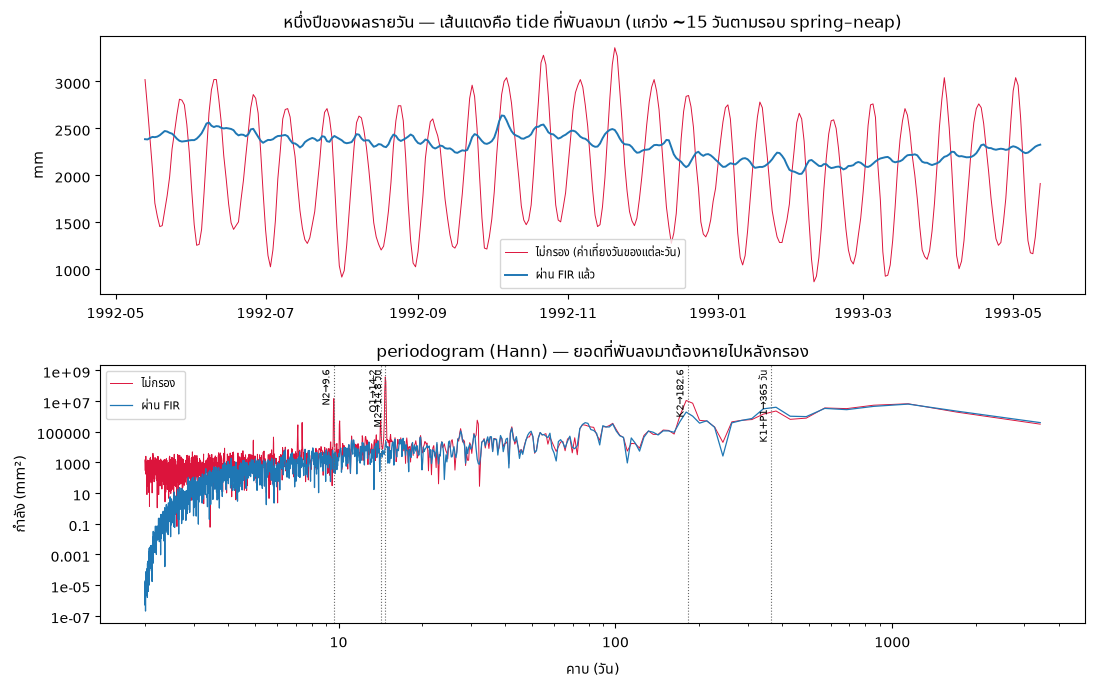

กำลังที่คาบ ~14.8 วัน ลดลง 42 dB หลังกรอง
ส่วนต่างค่าเฉลี่ย (ไม่กรอง − กรอง) = -288 mm  ← S2 ที่พับลงไปเป็นค่าคงที่


In [4]:
design = design_lowpass(f_pass=0.1, f_stop=0.5, atten_db=70.0, fs=24.0)
days, daily = hourly_to_daily(t, v, design)
nd_days, nd = naive_daily(t, v, hour=12)
assert np.array_equal(days, nd_days)

# ช่วงต่อเนื่องที่ยาวที่สุดที่ทั้งสองแบบมีค่าครบ
ok = np.isfinite(daily) & np.isfinite(nd)
e = np.flatnonzero(np.diff(np.r_[0, ok.astype(np.int8), 0]))
i = np.argmax(e[1::2] - e[::2]); a, b = e[2*i], e[2*i + 1]
print(f"ช่วงต่อเนื่องยาวสุด: {days[a]} → {days[b-1]} ({b-a} วัน)")

def periodogram(x):
    x = x - x.mean()
    w = np.hanning(len(x))
    P = np.abs(np.fft.rfft(x * w)) ** 2 / np.sum(w ** 2)
    return np.fft.rfftfreq(len(x), d=1.0), P

f1, P_naive = periodogram(nd[a:b]); _, P_filt = periodogram(daily[a:b])

fig, ax = plt.subplots(2, 1, figsize=(11, 7))
yr = slice(a, a + 365)
ax[0].plot(days[yr], nd[yr], lw=0.7, color="crimson", label="ไม่กรอง (ค่าเที่ยงวันของแต่ละวัน)")
ax[0].plot(days[yr], daily[yr], lw=1.4, color="C0", label="ผ่าน FIR แล้ว")
ax[0].set_ylabel("mm"); ax[0].legend(fontsize=8)
ax[0].set_title("หนึ่งปีของผลรายวัน — เส้นแดงคือ tide ที่พับลงมา (แกว่ง ~15 วันตามรอบ spring–neap)")

per = 1 / f1[1:]
ax[1].loglog(per, P_naive[1:], lw=0.7, color="crimson", label="ไม่กรอง")
ax[1].loglog(per, P_filt[1:], lw=0.9, color="C0", label="ผ่าน FIR")
for name, p_ in {"M2→14.8 วัน": 14.77, "O1→14.2": 14.19, "N2→9.6": 9.61,
                 "K1+P1→365 วัน": 365.2, "K2→182.6": 182.6}.items():
    ax[1].axvline(p_, color="0.4", ls=":", lw=0.8)
    ax[1].text(p_, P_naive[1:].max() * 3, name, rotation=90, fontsize=7, ha="right", va="top")
plain_log_ticks(ax[1])
ax[1].set_xlabel("คาบ (วัน)"); ax[1].set_ylabel("กำลัง (mm²)")
ax[1].set_title("periodogram (Hann) — ยอดที่พับลงมาต้องหายไปหลังกรอง"); ax[1].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIGURES / "w2-aliasing-before-after.png", dpi=130); plt.show()

# ยืนยันด้วยตัวเลข: กำลังที่คาบ 14.8 วัน (M2 ที่พับลงมา) ต้องลดลงเป็นหลักพันเท่า
k = np.argmin(np.abs(1 / np.maximum(f1, 1e-9) - 14.77))
ratio_db = 10 * np.log10(P_naive[k-2:k+3].max() / P_filt[k-2:k+3].max())
print(f"กำลังที่คาบ ~14.8 วัน ลดลง {ratio_db:.0f} dB หลังกรอง")
print(f"ส่วนต่างค่าเฉลี่ย (ไม่กรอง − กรอง) = {np.mean(nd[a:b] - daily[a:b]):+.0f} mm  ← S2 ที่พับลงไปเป็นค่าคงที่")
assert ratio_db > 30

### ทำไมที่คาบ 365 วันสองเส้นดูเกือบทับกัน — และทำไมนั่นอันตรายกว่าที่เห็น

ในสเปกตรัม log-log ความต่างระดับ 25% แทบมองไม่เห็น แต่สำหรับงานนี้มันใหญ่มาก เพราะวงรอบรายปี
และครึ่งปีคือสิ่งที่ `preprocess.detrend_deseason` ต้องตัดออกให้แม่น ⇒ วัดตรง ๆ ด้วย harmonic fit
บนทั้งบันทึก (least squares ไม่ต้องการกริดครบ จึงใช้ข้อมูลได้ทุกวัน)

In [5]:
td = (days - days[0]).astype(float)
def seasonal_amp(x):
    g = np.isfinite(x)
    cols = [np.ones(g.sum()), td[g]]
    for P in (365.2422, 182.6211):
        w = 2 * np.pi * td[g] / P
        cols += [np.cos(w), np.sin(w)]
    c = np.linalg.lstsq(np.column_stack(cols), x[g], rcond=None)[0]
    return np.hypot(c[2], c[3]), np.hypot(c[4], c[5])

a_f, s_f = seasonal_amp(daily)
a_n, s_n = seasonal_amp(nd)
print(f"                 วงรอบรายปี   วงรอบครึ่งปี")
print(f"  ผ่าน FIR       {a_f:8.1f} mm   {s_f:8.1f} mm")
print(f"  ไม่กรอง        {a_n:8.1f} mm   {s_n:8.1f} mm")
print(f"  ผิดไป          {100*(a_n/a_f-1):+7.0f} %    {100*(s_n/s_f-1):+7.0f} %")
assert s_n > 2 * s_f

                 วงรอบรายปี   วงรอบครึ่งปี
  ผ่าน FIR           80.1 mm       64.2 mm
  ไม่กรอง            60.1 mm      176.7 mm
  ผิดไป              -25 %       +175 %


**aliasing บิดวงรอบฤดูกาลได้ทั้งสองทาง**: K1+P1 ที่พับลงมา *หักล้าง* กับวงรอบรายปีจริง (เฟสสวนกัน)
จนเห็นเล็กลงราว 25% ส่วน K2 *บวก* เข้ากับวงรอบครึ่งปีจนพองขึ้นเกือบ 3 เท่า — ถ้าใช้ข้อมูลที่ไม่กรอง
เราจะสรุปผิดทั้งเรื่องขนาดของมรสุมและเรื่องสัดส่วนระหว่างวงรอบรายปีกับครึ่งปี


## 4. ออกแบบตัวกรอง — ทุกตัวเลขมีที่มา

| สเปก | ค่า | ที่มา |
| --- | --- | --- |
| $f_s$ | 24 ตัวอย่าง/วัน | ข้อมูลรายชั่วโมง |
| ขอบ stopband | 0.5 cpd | = Nyquist ของผลรายวัน ⇒ **ไม่มีอะไรพับได้เลย** |
| ขอบ passband | 0.1 cpd (คาบ 10 วัน) | ปลายทางคือรายเดือน (คาบ ≥ 60 วัน) ⇒ เผื่อ 6 เท่า |
| attenuation | 70 dB | M2 789 mm · รวมทุกตัว ~1,675 mm ⇒ ต้อง ≥ 64.5 dB ถึงเหลือ < 1 mm |

สูตร Kaiser (Oppenheim & Schafer eq. 7.62–7.63) — $A$ = attenuation (dB), $\Delta\omega$ = ความกว้างแถบเปลี่ยนผ่าน

$$\beta = 0.1102\,(A-8.7)\quad(A>50)\qquad\qquad M = \frac{A-8}{2.285\,\Delta\omega},\quad \Delta\omega=\frac{2\pi(f_{\text{stop}}-f_{\text{pass}})}{f_s}$$

$$h[n] = \underbrace{\frac{2f_c}{f_s}\,\operatorname{sinc}\!\left(\frac{2f_c}{f_s}(n-\alpha)\right)}_{\text{lowpass ในอุดมคติ}}\cdot\underbrace{\frac{I_0\!\left(\beta\sqrt{1-((n-\alpha)/\alpha)^2}\right)}{I_0(\beta)}}_{\text{หน้าต่าง Kaiser}},\qquad f_c=\frac{f_{\text{pass}}+f_{\text{stop}}}{2},\ \alpha=\frac{M}{2}$$

In [6]:
total_amp = sum(amp.values())
need_db = 20 * np.log10(total_amp / 1.0)
print(f"แอมพลิจูดรวมทุกองค์ประกอบ {total_amp:.0f} mm ⇒ ต้องการ ≥ {need_db:.1f} dB เพื่อให้เหลือ < 1 mm · ตั้งไว้ 70 dB")
print(f"\nbeta   = 0.1102 × (70 − 8.7) = {kaiser_beta(70):.4f}")
dw = 2 * np.pi * (0.5 - 0.1) / 24
print(f"Δω     = 2π × 0.4 / 24 = {dw:.5f} rad/ตัวอย่าง")
print(f"M      = (70 − 8)/(2.285 × Δω) = {(70-8)/(2.285*dw):.1f} ⇒ numtaps = {kaiser_numtaps(70, 0.1, 0.5, 24)} (ปัดขึ้นเป็นเลขคี่ ⇒ Type I)")
print(f"\nได้จริง: {design.numtaps} taps = {design.numtaps/24:.1f} วัน · หน่วง {(design.numtaps-1)//2} ชม. (ชดเชยแล้วใน fir_at)")
print(f"วัดจริง: stopband {design.measured_stopband_db():.2f} dB · passband ripple {design.measured_passband_ripple():.1e}")
assert design.measured_stopband_db() >= 70

# เทียบกับ scipy — ยืนยันว่าสูตรที่เขียนเองถูก (ไลบรารีใช้ตรวจเท่านั้น ไม่ได้ใช้ผลิตผล)
from scipy import signal
n_ref, beta_ref = signal.kaiserord(70.0, 0.4 / 12)
h_ref = signal.firwin(design.numtaps, design.cutoff, window=("kaiser", design.beta), fs=24.0)
print(f"\nscipy.kaiserord: numtaps={n_ref} beta={beta_ref:.4f}")
print(f"taps ของเรา vs scipy.firwin ต่างสูงสุด {np.abs(h_ref - design.taps).max():.1e}")
assert n_ref == design.numtaps and np.abs(h_ref - design.taps).max() < 1e-12

แอมพลิจูดรวมทุกองค์ประกอบ 1675 mm ⇒ ต้องการ ≥ 64.5 dB เพื่อให้เหลือ < 1 mm · ตั้งไว้ 70 dB

beta   = 0.1102 × (70 − 8.7) = 6.7553
Δω     = 2π × 0.4 / 24 = 0.10472 rad/ตัวอย่าง
M      = (70 − 8)/(2.285 × Δω) = 259.1 ⇒ numtaps = 261 (ปัดขึ้นเป็นเลขคี่ ⇒ Type I)

ได้จริง: 261 taps = 10.9 วัน · หน่วง 130 ชม. (ชดเชยแล้วใน fir_at)
วัดจริง: stopband 70.07 dB · passband ripple 4.8e-04



scipy.kaiserord: numtaps=261 beta=6.7553
taps ของเรา vs scipy.firwin ต่างสูงสุด 2.2e-19


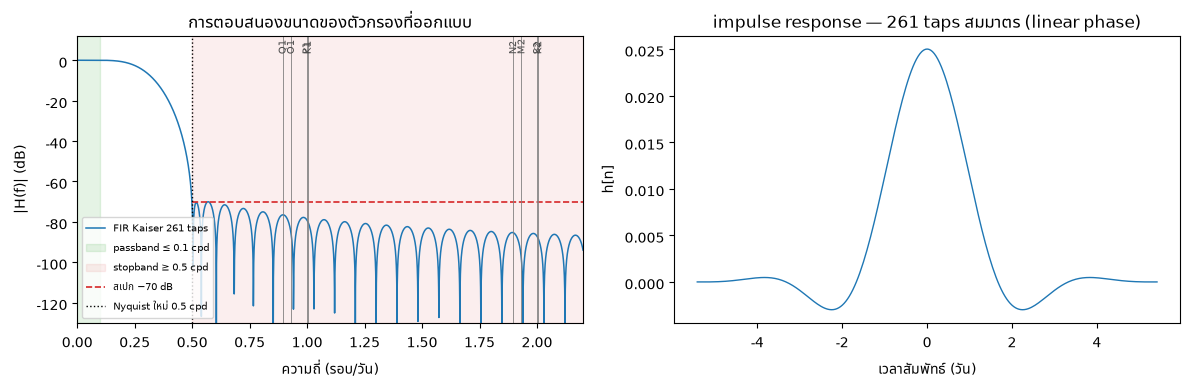

gain ที่แต่ละองค์ประกอบ และเศษที่เหลือหลังกรอง:
  M2:  -98.9 dB  ⇒  788.6 mm เหลือ 0.0090 mm
  S2:  -87.2 dB  ⇒  400.1 mm เหลือ 0.0175 mm
  N2:  -85.4 dB  ⇒  150.9 mm เหลือ 0.0081 mm
  K2:  -88.4 dB  ⇒  111.8 mm เหลือ 0.0042 mm
  K1:  -79.9 dB  ⇒  130.3 mm เหลือ 0.0132 mm
  O1:  -85.4 dB  ⇒   48.2 mm เหลือ 0.0026 mm
  P1:  -78.8 dB  ⇒   38.2 mm เหลือ 0.0044 mm
  Q1:  -76.6 dB  ⇒    7.2 mm เหลือ 0.0011 mm


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
plot_filter_response(ax[0], design, TIDES_CPD, fs_out=1.0)
ax[0].set_title("การตอบสนองขนาดของตัวกรองที่ออกแบบ")
n = np.arange(design.numtaps) - design.numtaps // 2
ax[1].plot(n / 24, design.taps, lw=1)
ax[1].set_xlabel("เวลาสัมพัทธ์ (วัน)"); ax[1].set_ylabel("h[n]")
ax[1].set_title(f"impulse response — {design.numtaps} taps สมมาตร (linear phase)")
fig.tight_layout(); fig.savefig(FIGURES / "w2-filter-response.png", dpi=130); plt.show()

print("gain ที่แต่ละองค์ประกอบ และเศษที่เหลือหลังกรอง:")
for k, g_ in zip(TIDES_CPD, design.gain_at(list(TIDES_CPD.values()))):
    print(f"  {k}: {20*np.log10(g_):6.1f} dB  ⇒ {amp[k]:6.1f} mm เหลือ {amp[k]*g_:.4f} mm")

### ทางเลือกของสเปก — แลกกันอย่างไร

ความยาวตัวกรองแปรผกผันกับความกว้างแถบเปลี่ยนผ่าน และแปรตรงกับ attenuation
ตารางนี้ช่วยตอบว่าทำไมเลือกแบบนี้ ไม่ใช่แบบอื่น

In [8]:
print(f"  {'passband':>9s} {'stopband':>9s} {'dB':>4s} {'taps':>6s} {'ยาว (วัน)':>10s}  หมายเหตุ")
for fp, fs_, A, note in [(0.1, 0.5, 70, "← ที่เลือก: ไม่มีอะไรพับเลย"),
                         (0.1, 0.9, 70, "ยอมให้ 0.5–0.9 cpd พับลงไปที่ 0.1–0.5 (นอกแถบที่สนใจ)"),
                         (0.1, 0.5, 60, "ต่ำกว่าที่ข้อมูลต้องการ (64.5 dB)"),
                         (0.1, 0.5, 90, "เกินจำเป็น"),
                         (0.3, 0.5, 70, "เก็บแถบสภาพอากาศ 3–10 วันไว้ด้วย")]:
    N = kaiser_numtaps(A, fp, fs_, 24)
    print(f"  {fp:9.1f} {fs_:9.1f} {A:4d} {N:6d} {N/24:10.1f}  {note}")

   passband  stopband   dB   taps  ยาว (วัน)  หมายเหตุ
        0.1       0.5   70    261       10.9  ← ที่เลือก: ไม่มีอะไรพับเลย
        0.1       0.9   70    131        5.5  ยอมให้ 0.5–0.9 cpd พับลงไปที่ 0.1–0.5 (นอกแถบที่สนใจ)
        0.1       0.5   60    219        9.1  ต่ำกว่าที่ข้อมูลต้องการ (64.5 dB)
        0.1       0.5   90    345       14.4  เกินจำเป็น
        0.3       0.5   70    521       21.7  เก็บแถบสภาพอากาศ 3–10 วันไว้ด้วย


แบบ stopband 0.9 cpd สั้นกว่า 2.4 เท่า แต่ Q1 (0.893 cpd) จะไปตกในแถบเปลี่ยนผ่านพอดี และต้องอธิบาย
เพิ่มอีกชั้นว่าทำไมการพับช่วง 0.5–0.9 cpd ไม่เสียหาย — ในเมื่อแบบเข้มคำนวณไม่ถึง 0.01 วินาที
(`fir_at` คำนวณเฉพาะ 1 ใน 24 ตัวอย่างที่เก็บ = หลักการเดียวกับ polyphase decimator) จึงไม่มีเหตุผลต้องประหยัด

## 5. ทดสอบ stopband ด้วยสัญญาณสังเคราะห์ (เกณฑ์ proposal §4)

ป้อน tide ทั้ง 8 องค์ประกอบ **ตัวละ 1 เมตร** (แรงกว่าของจริง 1.3–140 เท่า) เข้าโซ่เดียวกัน
แล้ววัดว่าเหลืออะไรในผลรายวัน

In [9]:
h_all = np.arange(len(t), dtype=float)
synth = sum(1000.0 * np.cos(2 * np.pi * f * h_all / 24 + k) for k, f in enumerate(TIDES_CPD.values()))
_, out = hourly_to_daily(t, synth, design)
_, raw_pick = naive_daily(t, synth)
res = np.nanmax(np.abs(out)); raw = np.nanmax(np.abs(raw_pick))
bound = 8000 * 10 ** (-70 / 20)
print(f"ขาเข้า: tide 8 ตัว × 1000 mm · ถ้าไม่กรอง ค่ารายวันแกว่งสูงสุด {raw:.0f} mm")
print(f"ขาออก: เหลือสูงสุด {res:.4f} mm  (ขอบบนตามสเปก 8000 × 10^(−70/20) = {bound:.2f} mm)")
print(f"attenuation ที่วัดได้จริง = {20*np.log10(raw/res):.0f} dB")
assert res < bound

ขาเข้า: tide 8 ตัว × 1000 mm · ถ้าไม่กรอง ค่ารายวันแกว่งสูงสุด 5085 mm
ขาออก: เหลือสูงสุด 0.2958 mm  (ขอบบนตามสเปก 8000 × 10^(−70/20) = 2.53 mm)
attenuation ที่วัดได้จริง = 85 dB


## 6. ชั้นรายวัน — เทียบกับตัวกรองทางการของ UHSLC

UHSLC เผยแพร่ค่ารายวันที่ผ่านตัวกรองน้ำขึ้นน้ำลงของเขาเองด้วย ⇒ ใช้เป็น**ตัวเทียบชั้นกลาง**
ที่แยกได้ว่าความต่างกับ PSMSL (ในหัวข้อถัดไป) มาจากขั้นรายวันหรือขั้นรายเดือน

รายวัน เรา vs UHSLC daily: n=12,203 วัน · offset -0.02 mm · RMS 3.03 mm · median|d| 1.91 mm · corr 0.99969


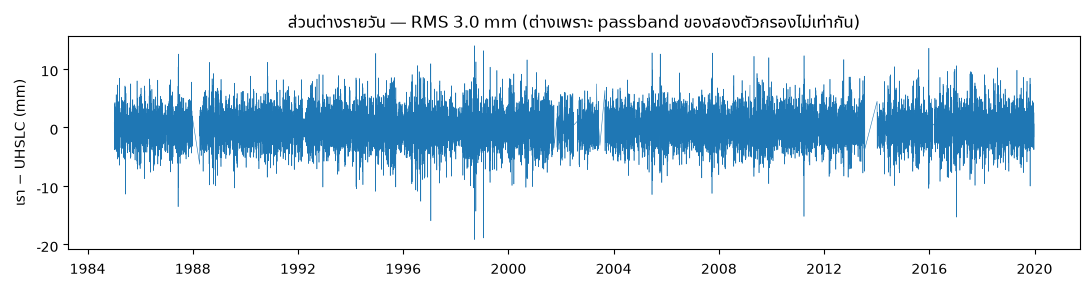

In [10]:
ud, uval = read_uhslc_daily(RAW / "uhslc" / "ko_taphao_noi_daily.csv")
c_day = compare(days, daily, ud, uval)
print(f"รายวัน เรา vs UHSLC daily: n={c_day.n:,} วัน · offset {c_day.offset:+.2f} mm · "
      f"RMS {c_day.rms:.2f} mm · median|d| {np.median(np.abs(c_day.diff)):.2f} mm · corr {c_day.corr:.5f}")

fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(c_day.keys, c_day.diff, lw=0.4)
ax.set_ylabel("เรา − UHSLC (mm)")
ax.set_title(f"ส่วนต่างรายวัน — RMS {c_day.rms:.1f} mm (ต่างเพราะ passband ของสองตัวกรองไม่เท่ากัน)")
fig.tight_layout(); fig.savefig(FIGURES / "w2-daily-vs-uhslc.png", dpi=130); plt.show()
assert c_day.rms < 5 and abs(c_day.offset) < 1

RMS 3 mm บนสัญญาณที่แกว่งเป็นเมตร — และ offset เป็นศูนย์ (ใช้ datum เดียวกัน) ส่วนที่เหลือมาจาก
passband ที่ไม่เท่ากัน: ของเราตัดที่ 0.1–0.5 cpd ส่วน UHSLC ใช้ตัวกรอง 119 จุดที่ปล่อยแถบสภาพอากาศ
2–10 วันผ่านไปได้มากกว่า ⇒ **ขั้นรายวันของเราเชื่อถือได้**

## 7. ชั้นรายเดือน — เทียบกับ PSMSL (คำตอบของ Q7)

In [11]:
months, monthly, n_days = daily_to_monthly(days, daily)
tp, vp = read_psmsl(RAW / "psmsl" / "ko_taphao_noi_monthly.rlrdata")
pm = decimal_year_to_month(tp)
c_all = compare(months, monthly, pm, vp)
print(f"ทั้งช่วง: n={c_all.n} เดือน · offset {c_all.offset:+.1f} mm · RMS {c_all.rms:.1f} mm · "
      f"median|d| {np.median(np.abs(c_all.diff)):.1f} mm · ต่างสูงสุด {c_all.max_abs:.0f} mm")

# ตัวเปรียบเทียบ: ถ้าความต่างมาจากตัวกรองของเรา ตัวเปรียบเทียบที่ไม่ใช้ตัวกรองเราต้องได้ผลต่างออกไป
um, umv, _ = daily_to_monthly(ud, uval)
dm, dmv, _ = monthly_mean_direct(t, v)
for label, (k_, x_) in {"UHSLC daily → เฉลี่ยรายเดือน": (um, umv),
                        "เฉลี่ยตรงจากรายชั่วโมง (ไม่ผ่าน FIR)": (dm, dmv)}.items():
    c_ = compare(k_, x_, pm, vp)
    print(f"  {label:40s} RMS {c_.rms:.1f} mm")

ทั้งช่วง: n=375 เดือน · offset -4855.4 mm · RMS 58.1 mm · median|d| 29.4 mm · ต่างสูงสุด 405 mm
  UHSLC daily → เฉลี่ยรายเดือน             RMS 57.9 mm
  เฉลี่ยตรงจากรายชั่วโมง (ไม่ผ่าน FIR)     RMS 57.9 mm


**RMS ทั้งช่วง 58 mm แต่ตัวเปรียบเทียบที่ไม่ได้ใช้ตัวกรองของเราเลยก็ได้ 58 mm เท่ากัน** ⇒
ความต่างก้อนนี้ไม่ได้มาจากโซ่ของเรา มันคือ **UHSLC กับ PSMSL ไม่ตรงกันเอง** ต้องดูส่วนต่างตามเวลา

เอกสารของ PSMSL สถานี 446 (`psmsl.org/data/obtaining/stations/446.php`) บันทึกไว้ว่า
> *From 1987 onwards the benchmark was BM 105 … In 1988 the datum was raised 14mm …
> In 1998 the primary benchmark became AS-1/2531*

และปี 2004 คือปีสึนามิที่มาตรวัดเสียหาย

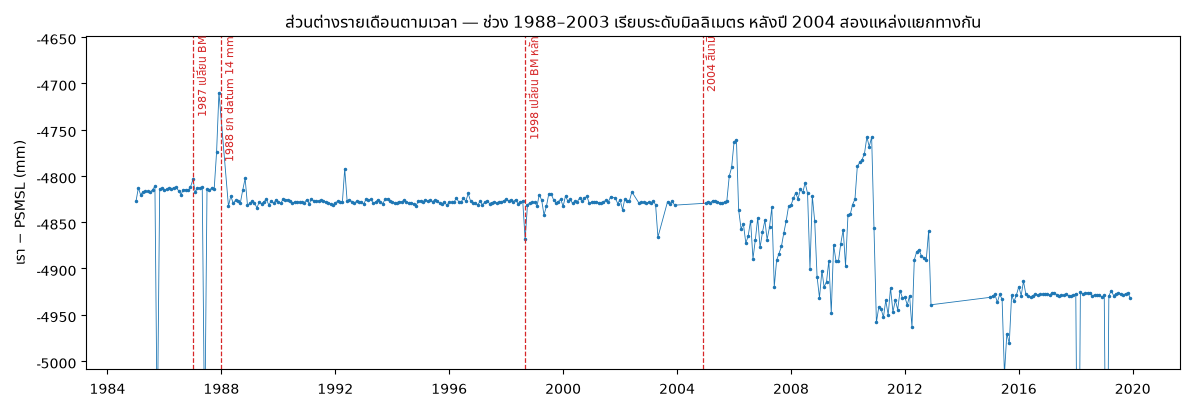

  ช่วง                          n  offset ค่ากลาง     RMS  median|d|  ภายใน ±5 mm
  1985–1987 (ก่อนยก datum)     36         -4814.7   65.38       2.03          78%
  1988–2005 (นิ่ง ยุคแรก)     195         -4828.0    6.70       1.22          90%
  2006–2012 (ไม่นิ่ง)          84         -4872.9   52.99      40.35           8%
  2015–2019 (นิ่งอีกครั้ง)     60         -4928.8   59.54       1.10          85%

⚠️ ขั้นบันไดของ datum ระหว่างสองยุคที่นิ่ง = -100.7 mm


In [12]:
raw_diff = c_all.diff + c_all.offset
fig, ax = plt.subplots(figsize=(12, 4.2))
ax.plot(c_all.keys, raw_diff, ".-", lw=0.6, ms=3)
ax.set_ylim(np.median(raw_diff) - 180, np.median(raw_diff) + 180)
events = {"1987 เปลี่ยน BM": "1987-01", "1988 ยก datum 14 mm": "1988-01",
          "1998 เปลี่ยน BM หลัก": "1998-09", "2004 สึนามิ": "2004-12"}
for lab, when in events.items():
    ax.axvline(np.datetime64(when), color="C3", ls="--", lw=0.9)
    ax.text(np.datetime64(when), ax.get_ylim()[1], " " + lab, rotation=90, va="top", fontsize=8, color="C3")
ax.set_ylabel("เรา − PSMSL (mm)")
ax.set_title("ส่วนต่างรายเดือนตามเวลา — ช่วง 1988–2003 เรียบระดับมิลลิเมตร หลังปี 2004 สองแหล่งแยกทางกัน")
fig.tight_layout(); fig.savefig(FIGURES / "w2-monthly-vs-psmsl.png", dpi=130); plt.show()

periods = {"1985–1987 (ก่อนยก datum)": ("1985-01", "1988-01"),
           "1988–2005 (นิ่ง ยุคแรก)": ("1988-01", "2006-01"),
           "2006–2012 (ไม่นิ่ง)": ("2006-01", "2013-01"),
           "2015–2019 (นิ่งอีกครั้ง)": ("2015-01", "2020-01")}
stats = {}
print(f"  {'ช่วง':26s} {'n':>4s} {'offset ค่ากลาง':>15s} {'RMS':>7s} {'median|d|':>10s} {'ภายใน ±5 mm':>12s}")
for lab, (lo, hi) in periods.items():
    sel = (months >= np.datetime64(lo)) & (months < np.datetime64(hi))
    c_ = compare(months[sel], monthly[sel], pm, vp)
    stats[lab] = c_
    rob = c_.diff + c_.offset - c_.median_offset     # วัดรอบค่ากลาง — ทนต่อค่าโดดไม่กี่เดือน
    print(f"  {lab:26s} {c_.n:4d} {c_.median_offset:15.1f} {c_.rms:7.2f} "
          f"{np.median(np.abs(rob)):10.2f} {np.mean(np.abs(rob) <= 5):12.0%}")
step = stats["2015–2019 (นิ่งอีกครั้ง)"].median_offset - stats["1988–2005 (นิ่ง ยุคแรก)"].median_offset
print(f"\n⚠️ ขั้นบันไดของ datum ระหว่างสองยุคที่นิ่ง = {step:+.1f} mm")
c_a = stats["1988–2005 (นิ่ง ยุคแรก)"]
assert np.median(np.abs(c_a.diff + c_a.offset - c_a.median_offset)) < 2
assert abs(step) > 50

**อ่านตารางนี้อย่างไร** — สองแหล่ง*ตรงกันระดับมิลลิเมตร*ในสองยุค (1988–2005 และ 2015–2019)
แต่ระดับอ้างอิงของยุคหลังต่ำลงไป **~101 mm** และช่วง 2006–2012 ส่วนต่างเดินไปมาไม่นิ่ง
(RMS ของยุค 2015–2019 สูงเพราะมีค่าโดดไม่กี่เดือน — จึงวัด median|d| และสัดส่วนภายใน ±5 mm
รอบ**ค่ากลาง**ของส่วนต่าง ไม่ใช่รอบค่าเฉลี่ยที่ถูกค่าโดดดึงไป)

เอกสารของ PSMSL ไม่ได้บันทึกเหตุการณ์ datum ใดหลังปี 2004 ⇒ **ตอนนี้ยังบอกไม่ได้ว่าขั้นบันไดนี้อยู่ใน
แหล่งไหน** (ทั้งสองแหล่งมาจากมาตรวัดตัวเดียวกัน ดังนั้นการเคลื่อนตัวของแผ่นดินจริงอธิบายความต่าง
*ระหว่างแหล่ง* ไม่ได้ ต้องเป็นเรื่องการอ้างอิง datum ของฝั่งใดฝั่งหนึ่ง)

### ส่วนต่างที่เหลือในช่วง 1985–2003 มาจากไหน — ไล่ทีละเดือน

In [13]:
sel = months < np.datetime64("2004-01")
c_pre = compare(months[sel], monthly[sel], pm, vp)
d_pre = c_pre.diff + c_pre.offset - np.median(c_pre.diff + c_pre.offset)   # อ้างอิงค่ากลาง ทนต่อค่าโดด
big = np.abs(d_pre) > 10
print(f"เดือนก่อนปี 2004 ที่ต่างเกิน 10 mm: {big.sum()} จาก {c_pre.n} เดือน\n")
print(f"  {'เดือน':8s} {'ต่าง':>8s} {'วันที่เราใช้ได้':>14s}  คำอธิบาย")
for k_, d_ in zip(c_pre.keys[big], d_pre[big]):
    nd_ = n_days[months == k_][0]
    if np.datetime64("1985-01") <= k_ < np.datetime64("1987-11") and 8 < d_ < 30:
        why = "ช่วงก่อนยก datum 14 mm"
    elif abs(d_) > 200:
        why = "ค่าโดดของ PSMSL (ดูตารางถัดไป)"
    elif k_ in (np.datetime64("1987-11"), np.datetime64("1987-12")):
        why = "รอยต่อเปลี่ยน benchmark ปี 1987"
    elif k_ == np.datetime64("1998-09"):
        why = "เดือนที่เปลี่ยน benchmark หลักปี 1998"
    elif nd_ < 25:
        why = f"เดือนไม่เต็ม ({nd_} วัน) ค่าเฉลี่ยจึงคนละชุดวันกัน"
    else:
        why = "—"
    print(f"  {str(k_):8s} {d_:+8.1f} {nd_:14d}  {why}")

เดือนก่อนปี 2004 ที่ต่างเกิน 10 mm: 38 จาก 219 เดือน

  เดือน        ต่าง วันที่เราใช้ได้  คำอธิบาย
  1985-02     +14.9             28  ช่วงก่อนยก datum 14 mm
  1985-04     +10.5             30  ช่วงก่อนยก datum 14 mm
  1985-05     +10.9             31  ช่วงก่อนยก datum 14 mm
  1985-06     +10.9             30  ช่วงก่อนยก datum 14 mm
  1985-08     +12.8             31  ช่วงก่อนยก datum 14 mm
  1985-09     +16.4             30  ช่วงก่อนยก datum 14 mm
  1985-10    -253.7             31  ค่าโดดของ PSMSL (ดูตารางถัดไป)
  1985-11     +13.7             30  ช่วงก่อนยก datum 14 mm
  1985-12     +14.2             31  ช่วงก่อนยก datum 14 mm
  1986-01     +12.1             31  ช่วงก่อนยก datum 14 mm
  1986-02     +13.0             28  ช่วงก่อนยก datum 14 mm
  1986-03     +14.3             31  ช่วงก่อนยก datum 14 mm
  1986-04     +13.7             30  ช่วงก่อนยก datum 14 mm
  1986-05     +15.0             31  ช่วงก่อนยก datum 14 mm
  1986-06     +15.2             30  ช่วงก่อนยก datum 14 mm
  1986-

In [14]:
print("สองเดือนที่ต่าง ~255 mm: เทียบกับเดือนข้างเคียงของแต่ละแหล่ง (หน่วย mm ของแต่ละ datum)\n")
for bad in ("1985-10", "1987-06"):
    print(f"  {bad}")
    for dm_ in (-1, 0, 1):
        k_ = np.datetime64(bad) + np.timedelta64(dm_, "M")
        ours = monthly[months == k_][0]; uh = umv[um == k_][0]; ps = vp[pm == k_][0]
        print(f"     {k_}   เรา {ours:8.1f}   UHSLC daily {uh:8.1f}   PSMSL {ps:8.1f}")
print("\n⇒ PSMSL กระโดดขึ้น ~300 mm แล้วกลับลงมาในเดือนเดียว ขณะที่สองแหล่งจาก UHSLC ที่ประมวลผลคนละทาง")
print("   ต่อเนื่องเรียบและตรงกันเอง ⇒ ค่าโดดอยู่ฝั่ง PSMSL ไม่ใช่ฝั่งโซ่ของเรา")

สองเดือนที่ต่าง ~255 mm: เทียบกับเดือนข้างเคียงของแต่ละแหล่ง (หน่วย mm ของแต่ละ datum)

  1985-10
     1985-09   เรา   2319.7   UHSLC daily   2319.8   PSMSL   7131.0
     1985-10   เรา   2387.6   UHSLC daily   2387.8   PSMSL   7469.0
     1985-11   เรา   2372.0   UHSLC daily   2372.2   PSMSL   7186.0
  1987-06
     1987-05   เรา   2337.5   UHSLC daily   2337.6   PSMSL   7150.0
     1987-06   เรา   2411.0   UHSLC daily   2410.9   PSMSL   7498.0
     1987-07   เรา   2433.3   UHSLC daily   2433.4   PSMSL   7248.0

⇒ PSMSL กระโดดขึ้น ~300 mm แล้วกลับลงมาในเดือนเดียว ขณะที่สองแหล่งจาก UHSLC ที่ประมวลผลคนละทาง
   ต่อเนื่องเรียบและตรงกันเอง ⇒ ค่าโดดอยู่ฝั่ง PSMSL ไม่ใช่ฝั่งโซ่ของเรา


## 8. ชั้นรายปี

In [15]:
years, annual, n_mon = monthly_to_annual(months, monthly)
ta, va = read_psmsl(RAW / "psmsl" / "ko_taphao_noi_annual.rlrdata")
c_yr = compare(years, annual, np.floor(ta).astype(int), va)
print(f"รายปี (ต้องครบ 12 เดือน): n={c_yr.n} ปี · RMS {c_yr.rms:.1f} mm · median|d| {np.median(np.abs(c_yr.diff)):.1f} mm")
sel = (c_yr.keys >= 1988) & (c_yr.keys <= 2003)
d_ = c_yr.diff[sel] - c_yr.diff[sel].mean()
print(f"เฉพาะ 1988–2003: n={sel.sum()} ปี · RMS {np.sqrt(np.mean(d_**2)):.2f} mm")

รายปี (ต้องครบ 12 เดือน): n=28 ปี · RMS 48.6 mm · median|d| 32.0 mm
เฉพาะ 1988–2003: n=12 ปี · RMS 1.54 mm


## 9. ด่านสุดท้าย — ต้องได้ผลเดียวกับสคริปต์

In [16]:
d = np.load(ROOT / "data" / "processed" / "decimation.npz", allow_pickle=True)
assert np.allclose(d["taps"], design.taps, atol=0, rtol=0)
assert np.allclose(d["daily"], daily, equal_nan=True)
assert np.allclose(d["monthly"], monthly, equal_nan=True)
assert np.allclose(d["annual"], annual, equal_nan=True)
res = json.loads(str(d["results"]))
print("✅ โน้ตบุ๊กกับ scripts/verify_decimation.py ให้ผลตรงกันทุกค่า")
print(f"   รายวัน vs UHSLC RMS {res['daily_vs_uhslc']['rms']:.2f} mm · "
      f"รายเดือน 1988–2005 median|d| {res['monthly 1988–2005 (datum นิ่ง ยุคแรก)']['median_abs']:.2f} mm · "
      f"ขั้นบันได datum {res['datum_step_mm']:+.1f} mm")
assert abs(res["datum_step_mm"] - step) < 1e-9

✅ โน้ตบุ๊กกับ scripts/verify_decimation.py ให้ผลตรงกันทุกค่า
   รายวัน vs UHSLC RMS 3.03 mm · รายเดือน 1988–2005 median|d| 1.22 mm · ขั้นบันได datum -100.7 mm


## สรุป — คำตอบของ Q7

| ชั้น | เทียบกับ | ผล |
| --- | --- | --- |
| ตัวกรอง | `scipy.firwin` / `kaiserord` | 261 taps · β 6.7553 ตรงกันทุกตัว · taps ต่าง < 1e-18 |
| stopband | สเปก 70 dB | วัดได้ 70.07 dB · tide 1 m ทั้ง 8 ตัวเหลือ < 2.5 mm |
| รายวัน | UHSLC daily | **RMS 3.0 mm** · offset 0 |
| รายเดือน 1988–2005 | PSMSL | **median \|d\| 1.2 mm** · 90% ของเดือนต่างไม่เกิน ±5 mm |
| รายเดือน 2015–2019 | PSMSL | median \|d\| 1.1 mm · 85% ภายใน ±5 mm — ตรงกันเท่ากัน แต่ **offset ขยับไป ~101 mm** |
| รายเดือน ทั้งช่วง | PSMSL | RMS 58 mm — **ไม่ได้มาจากโซ่ของเรา** (ตัวเปรียบเทียบที่ไม่ใช้โซ่เราได้ 58 mm เท่ากัน) |
| ไม่กรองเลย | PSMSL | RMS 152 mm · offset ขยับ 290 mm (= S2 พับลงไปเป็นค่าคงที่) · วงรอบรายปีเล็กลง ~25% · ครึ่งปีพอง ~3 เท่า |

**ที่มาของผลต่างที่เหลือ** (เกณฑ์ proposal ให้อธิบาย): ก่อนปี 2004 เกือบทุกเดือนที่ต่างเกิน 10 mm
ตรงกับเหตุการณ์ datum ที่ PSMSL จดไว้เอง (ยก datum 14 mm ปี 1988 · เปลี่ยน benchmark ปี 1987/1998)
เดือนที่มีข้อมูลไม่เต็ม หรือ**ค่าโดดสองเดือนในข้อมูล PSMSL เอง** (1985-10, 1987-06)

### ⚠️ ผลกระทบต่อการวิเคราะห์หลัก — ต้องรู้ก่อน W4

ตัวแปรตาม Y ของโปรเจกต์คือ **PSMSL รายเดือนของ KO TAPHAO NOI** (สถานีหลักที่จะรายงาน) Q7 เลยให้
ผลพลอยได้ที่สำคัญกว่าตัวคำถามเอง:

1. **ค่าโดด 2 เดือน (~+255 mm) ใน PSMSL** — อยู่นอกหน้าต่างวิเคราะห์หลัก (1951–2023 ครอบคลุม
   แต่ทั้งสองเดือนอยู่ในนั้น ⇒ **อยู่ในข้อมูลที่ใช้จริง**) ต้องตัดสินว่าจะทำเครื่องหมายเป็นช่องว่างไหม
2. **ขั้นบันไดของ datum ~101 mm ระหว่างยุค 1988–2005 กับ 2015–2019** และช่วง 2006–2012 ที่ไม่นิ่ง
   โดยไม่มีเอกสารของ PSMSL อธิบาย ⇒ ถ้าขั้นบันไดอยู่ใน PSMSL (ตัวแปร Y ของเรา) มันคือ step ขนาด
   ~1–1.5 เท่าของส่วนเบี่ยงเบนของ anomaly ซึ่งจะใส่พลังงานปลอมลงแถบคาบยาว (8–16 ปี) และบิดแนวโน้ม
   ⇒ **ต้องทำ sensitivity ใน W7**: ใช้ผลรายเดือนจากโซ่นี้ (1985–2019) เป็น Y ทางเลือก แล้วดูว่า
   ข้อสรุปของ Q1 เปลี่ยนไหม โดยเฉพาะแถบ 8–16 ปี
